<div align="center"><h1>Arrabal · GoalZone</h1><h3>Solución docente: North Star y árboles de métricas</h3></div>

**Ejecutable desde Google Colab sin instalar Python en tu PC.** Descarga automáticamente el CSV público de GoalZone, crea los DataFrames, calcula tasas e intervalos de confianza, contrasta las cinco asociaciones y representa un gráfico interactivo con filtro por categoría.

**Pregunta:** ¿Puede una variable estar correlacionada con la asistencia sin ser una palanca causal?

> El dataset es un caso didáctico; las cifras se calcularán al ejecutar. La North Star ideal de experiencia satisfactoria recurrente no es observable con estos campos.

### 1. Bibliotecas y definiciones

No se necesitan rutas Windows ni archivos previos. En Google Colab estas dependencias normalmente están disponibles.

In [1]:
import io
import json
import math
import textwrap
import urllib.error
import urllib.request
from pathlib import Path
from IPython.display import display, Image
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency, pointbiserialr
import plotly.graph_objects as go
import matplotlib
matplotlib.use("Agg")  # Solo para el PNG del árbol; el gráfico interactivo usa Plotly.
import matplotlib.pyplot as plt

DATASET_URL = "https://raw.githubusercontent.com/xrander/fitness_class_project/master/fitness_class_2212.csv"
DATASET_FALLBACK = "https://raw.githubusercontent.com/MarcoABarrera/Fitness_class_dataset/main/fitness_class_2212.csv"
ORANGE = "#FF9500"
PURPLE = "#3C26F1"
BLACK = "#191919"
TENURE_BINS = [-np.inf, 3, 6, 12, 24, np.inf]
TENURE_LABELS = ["0–3", "4–6", "7–12", "13–24", "25+"]
FEATURES = {
    "months_as_member": "Antigüedad del socio",
    "days_before_num": "Antelación de reserva",
    "category": "Categoría de clase",
    "time": "Horario",
    "day_of_week_normalized": "Día de la semana",
}
NEEDED = {"booking_id", "months_as_member", "days_before", "category", "time", "day_of_week", "attended"}
print("Dependencias cargadas. Fuente:", DATASET_URL)

Dependencias cargadas. Fuente: https://raw.githubusercontent.com/xrander/fitness_class_project/master/fitness_class_2212.csv


### 2. Funciones reutilizables

Es el mismo núcleo de cálculo que utiliza el flujo automático de GitHub Actions; la capa de visualización interactiva no necesita un backend gráfico de Jupyter.

In [2]:
def download_csv(path: Path, urls: tuple[str, ...] = (DATASET_URL, DATASET_FALLBACK)) -> str:
    """Descarga CSV y verifica esquema; NUNCA reemplaza por datos sintéticos."""
    errors = []
    path.parent.mkdir(parents=True, exist_ok=True)
    for url in urls:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 ArrabalKPILab/1.0"})
            with urllib.request.urlopen(req, timeout=35) as response:
                contents = response.read()
            if len(contents) < 1000 or contents[:100].lstrip().lower().startswith((b"<html", b"<!doctype")):
                raise ValueError("No se ha recibido un CSV válido")
            from io import BytesIO
            header = pd.read_csv(BytesIO(contents), nrows=0).columns.tolist()
            if not NEEDED.issubset(header):
                raise ValueError(f"Esquema incompatible: {sorted(NEEDED - set(header))}")
            tmp = path.with_suffix(".partial")
            tmp.write_bytes(contents)
            tmp.replace(path)
            return url
        except (ValueError, OSError, urllib.error.URLError, pd.errors.ParserError) as err:
            errors.append(f"{url}: {err}")
    raise RuntimeError("No se pudo descargar el CSV original:\n" + "\n".join(errors))


def clean_goalzone(raw: pd.DataFrame) -> tuple[pd.DataFrame, dict]:
    missing = NEEDED - set(raw.columns)
    if missing:
        raise ValueError(f"Esquema GoalZone incompleto: {sorted(missing)}")
    d = raw.copy()
    d["booking_id"] = d["booking_id"].astype("string").str.strip()
    duplicates = int(d["booking_id"].duplicated().sum())
    if duplicates:
        raise ValueError(f"booking_id duplicado: {duplicates} (se requiere 1 fila por reserva)")
    d["attended"] = pd.to_numeric(d["attended"], errors="coerce")
    bad_target = ~d["attended"].isin([0, 1])
    d.loc[bad_target, "attended"] = np.nan
    d["months_as_member"] = pd.to_numeric(d["months_as_member"], errors="coerce")
    d["days_before_num"] = pd.to_numeric(
        d["days_before"].astype("string").str.extract(r"(\d+(?:\.\d+)?)", expand=False), errors="coerce"
    )
    d["category"] = d["category"].astype("string").str.strip().replace({"-": pd.NA, "": pd.NA})
    d["time"] = d["time"].astype("string").str.upper().str.strip().replace({"": pd.NA})
    weekdays = {"mon": "Lunes", "tue": "Martes", "wed": "Miércoles", "thu": "Jueves", "fri": "Viernes", "sat": "Sábado", "sun": "Domingo"}
    d["day_of_week_normalized"] = d["day_of_week"].astype("string").str.strip().str.lower().str[:3].map(weekdays)
    d["tenure_group"] = pd.cut(d["months_as_member"], TENURE_BINS, labels=TENURE_LABELS)
    quality = {
        "filas_origen": len(raw),
        "reservas_con_target_valido": int(d["attended"].notna().sum()),
        "reservas_sin_target_valido": int(bad_target.sum()),
        "ids_duplicados": duplicates,
        "nulos_antiguedad": int(d["months_as_member"].isna().sum()),
        "nulos_anticipacion": int(d["days_before_num"].isna().sum()),
        "nulos_categoria": int(d["category"].isna().sum()),
        "nulos_dia_normalizado": int(d["day_of_week_normalized"].isna().sum()),
    }
    return d, quality


def wilson_interval(successes: int, total: int, z: float = 1.959963984540054) -> tuple[float, float]:
    if total <= 0:
        return (math.nan, math.nan)
    p = successes / total
    zz = z * z
    denominator = 1 + zz / total
    centre = (p + zz / (2 * total)) / denominator
    margin = z * math.sqrt(p * (1 - p) / total + zz / (4 * total * total)) / denominator
    return max(0, centre - margin), min(1, centre + margin)


def segment_rates(df: pd.DataFrame, group: str) -> pd.DataFrame:
    d = df.dropna(subset=["attended", group])
    out = d.groupby(group, observed=True).agg(
        reservas=("attended", "size"), asistencias=("attended", "sum")
    ).reset_index().rename(columns={group: "segmento"})
    out["asistencias"] = out["asistencias"].astype(int)
    out["tasa_asistencia"] = out["asistencias"] / out["reservas"]
    intervals = [wilson_interval(int(s), int(n)) for s, n in zip(out["asistencias"], out["reservas"])]
    out["ic95_inf"] = [v[0] for v in intervals]
    out["ic95_sup"] = [v[1] for v in intervals]
    out["segmento"] = out["segmento"].astype(str)
    return out


def metric_association(df: pd.DataFrame, feature: str) -> dict:
    x = df[feature]
    numeric = feature in ("months_as_member", "days_before_num")
    if numeric:
        pair = pd.DataFrame({"x": pd.to_numeric(x, errors="coerce"), "y": df["attended"]}).replace([np.inf, -np.inf], np.nan).dropna()
        method = "r punto-biserial"
    else:
        pair = pd.DataFrame({"x": x.astype("string"), "y": df["attended"]}).dropna()
        method = "V de Cramér (sin signo)"
    base = {"metrica": feature, "nombre": FEATURES[feature], "metodo": method, "n": len(pair), "coeficiente": np.nan, "p_value": np.nan}
    if len(pair) < 20 or pair["x"].nunique() < 2 or pair["y"].nunique() < 2:
        return base
    if numeric:
        r, p = pointbiserialr(pair["y"], pair["x"])
        base.update(coeficiente=float(r), p_value=float(p))
    else:
        contingency = pd.crosstab(pair["x"], pair["y"])
        chi2, p, _, _ = chi2_contingency(contingency, correction=False)
        v = math.sqrt((chi2 / len(pair)) / (min(contingency.shape) - 1))
        base.update(coeficiente=float(v), p_value=float(p))
    return base


def adjust_bh(pvalues: pd.Series) -> pd.Series:
    ps = pd.to_numeric(pvalues, errors="coerce")
    valid = ps.dropna().sort_values()
    q = pd.Series(np.nan, index=ps.index, dtype=float)
    if len(valid):
        ranked = valid * len(valid) / np.arange(1, len(valid) + 1)
        q.loc[valid.index] = ranked[::-1].cummin()[::-1].clip(upper=1)
    return q


def compute_metrics(d: pd.DataFrame) -> tuple[dict, pd.DataFrame]:
    eligible = d["attended"].notna()
    n = int(eligible.sum())
    attended = int(d.loc[eligible, "attended"].sum())
    lo, hi = wilson_interval(attended, n)
    kpi = {"reservas_elegibles": n, "asistencias_confirmadas": attended,
           "tasa_asistencia": attended / n if n else None, "tasa_ic95_inf": lo, "tasa_ic95_sup": hi,
           "relacion_estructural": "asistencias = reservas_elegibles × tasa_asistencia",
           "unidad": "reserva", "limitacion": "Proxy, no mide satisfacción ni usuarios recurrentes"}
    corr = pd.DataFrame([metric_association(d, f) for f in FEATURES])
    corr["q_value_bh"] = adjust_bh(corr["p_value"])
    corr["significativo_fdr_5pct"] = corr["q_value_bh"].lt(0.05).fillna(False)
    return kpi, corr


def plot_tree(corr: pd.DataFrame, dest: Path) -> None:
    fig, ax = plt.subplots(figsize=(15, 7))
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")
    fig.patch.set_facecolor("#FFFFFF")
    ax.text(.5, .96, "GoalZone · árbol de métricas y asociaciones", ha="center", fontsize=20, weight="bold", color=BLACK)
    ax.text(.50, .79, "TASA DE ASISTENCIA · proxy por reserva", ha="center", fontsize=14,
            color="white", weight="bold", bbox=dict(boxstyle="round,pad=.8", fc=PURPLE, ec="none"))
    positions = np.linspace(.105, .895, len(FEATURES))
    for idx, (feature, name) in enumerate(FEATURES.items()):
        row = corr[corr["metrica"] == feature].iloc[0]
        coef = row["coeficiente"]
        short = "r" if "biserial" in row["metodo"] else "V"
        coef_label = "No estimable" if pd.isna(coef) else f"{short} = {coef:+.3f}" if short == "r" else f"V = {coef:.3f}"
        q = row["q_value_bh"]
        q_label = f"q = {q:.3g}" if pd.notna(q) else "q = n/d"
        x = positions[idx]
        ax.annotate("", xy=(x, .46), xytext=(.5, .73), arrowprops=dict(arrowstyle="->", lw=1.4, ls="--", color="#999999"))
        ax.text(x, .39, f"{textwrap.fill(name, width=17)}\n{coef_label}\n{q_label}",
                fontsize=10, ha="center", va="center", color=BLACK,
                bbox=dict(boxstyle="round,pad=.7", fc="#FFF5D6", ec=ORANGE, lw=1.1))
    ax.text(.5, .13, "Identidad de volumen: asistencias = reservas elegibles × tasa de asistencia", ha="center", fontsize=12, color=PURPLE, weight="bold")
    ax.text(.5, .05, "Flechas discontinuas = hipótesis exploratorias, NO causalidad.\n"
            "r y V de Cramér son métodos diferentes; no comparar su tamaño directamente.",
            ha="center", fontsize=10, color="#555555")
    fig.savefig(dest, dpi=155, bbox_inches="tight", facecolor="white")
    plt.close(fig)


def make_interactive_figure(d: pd.DataFrame) -> go.Figure:
    categories = ["Todas"] + sorted(d["category"].dropna().unique().tolist())
    fig = go.Figure()
    for i, category in enumerate(categories):
        subset = d if i == 0 else d[d["category"] == category]
        rate = segment_rates(subset, "tenure_group")
        # Conservar todos los tramos y representar 0 registros como NaN.
        rate = rate.set_index("segmento").reindex(TENURE_LABELS).reset_index()
        percentages = rate["tasa_asistencia"] * 100
        fig.add_trace(go.Bar(
            x=rate["segmento"], y=percentages, name=category, visible=(i == 0),
            marker_color=PURPLE if i == 0 else ORANGE,
            customdata=np.column_stack([rate["reservas"].fillna(0), rate["asistencias"].fillna(0)]),
            error_y={"type": "data", "array": ((rate["ic95_sup"] - rate["tasa_asistencia"]) * 100).fillna(0).tolist(),
                     "arrayminus": ((rate["tasa_asistencia"] - rate["ic95_inf"]) * 100).fillna(0).tolist(), "visible": True},
            hovertemplate="Antigüedad: %{x} meses<br>Asistencia: %{y:.1f}%<br>Reservas: %{customdata[0]:.0f}<br>Asistencias: %{customdata[1]:.0f}<extra></extra>",
        ))
    buttons = []
    for idx, category in enumerate(categories):
        visibility = [j == idx for j in range(len(categories))]
        buttons.append(dict(label=category, method="update", args=[{"visible": visibility}, {"title": f"Asistencia por antigüedad · {category}"}]))
    fig.update_layout(
        title="Asistencia por antigüedad · Todas", title_x=.5,
        xaxis_title="Antigüedad del socio (meses)", yaxis_title="Tasa de asistencia (%)",
        yaxis={"range": [0, 105]}, height=530,
        margin=dict(l=52, r=25, t=110, b=65), showlegend=False,
        paper_bgcolor="#FFFFFF", plot_bgcolor="#FFFFFF",
        updatemenus=[dict(type="dropdown", x=.01, y=1.24, xanchor="left", yanchor="top", buttons=buttons,
                         bgcolor="#FFF5D6", bordercolor=ORANGE, showactive=True)],
        annotations=[dict(text="Filtrar categoría:", x=.01, y=1.30, xref="paper", yref="paper", showarrow=False, xanchor="left")],
        font={"family": "Arial, sans-serif", "color": BLACK},
    )
    return fig


### 3. Cargar el dataset original y validar el grano

Una fila representa una **reserva**. Se rechazan IDs de reserva duplicados.

In [3]:
csv_path = Path("fitness_class_2212.csv")
fuente = download_csv(csv_path)
raw = pd.read_csv(csv_path, dtype={"booking_id": "string"})
df, calidad = clean_goalzone(raw)
print("Fuente descargada:", fuente)
print("Dimensiones del DataFrame:", df.shape)
display(df.head())
display(pd.DataFrame([calidad]).T.rename(columns={0: "valor"}))

Fuente descargada: https://raw.githubusercontent.com/xrander/fitness_class_project/master/fitness_class_2212.csv
Dimensiones del DataFrame: (1500, 11)


,booking_id,months_as_member,weight,days_before,day_of_week,time,category,attended,days_before_num,day_of_week_normalized,tenure_group
0,0001,17,79.56,8,Wed,PM,Strength,0.0,8,Miércoles,13–24
1,0002,10,79.01,2,Mon,AM,HIIT,0.0,2,Lunes,7–12
2,0003,16,74.53,14,Sun,AM,Strength,0.0,14,Domingo,13–24
3,0004,5,86.12,10,Fri,AM,Cycling,0.0,10,Viernes,4–6
4,0005,15,69.29,8,Thu,AM,HIIT,0.0,8,Jueves,13–24


,valor
filas_origen,1500
reservas_con_target_valido,1500
reservas_sin_target_valido,0
ids_duplicados,0
nulos_antiguedad,0
nulos_anticipacion,0
nulos_categoria,13
nulos_dia_normalizado,0


### 4. KPIs y asociaciones

La tasa de asistencia es una **proxy observable**, no una North Star verificada. Ajustamos los p-values con Benjamini–Hochberg.

In [4]:
kpi, correlaciones = compute_metrics(df)
print("Reservas válidas:", kpi["reservas_elegibles"])
print("Asistencias:", kpi["asistencias_confirmadas"])
print("Tasa de asistencia:", f'{kpi["tasa_asistencia"]:.1%}')
print("IC Wilson 95 %:", f'[{kpi["tasa_ic95_inf"]:.1%}; {kpi["tasa_ic95_sup"]:.1%}]')
display(correlaciones)
display(segment_rates(df, "tenure_group"))

Reservas válidas: 1500
Asistencias: 454
Tasa de asistencia: 30.3%
IC Wilson 95 %: [28.0%; 32.6%]


,metrica,nombre,metodo,n,coeficiente,p_value,q_value_bh,significativo_fdr_5pct
0,months_as_member,Antigüedad del socio,r punto-biserial,1500,0.485526,1.501053e-89,7.505267e-89,True
1,days_before_num,Antelación de reserva,r punto-biserial,1500,0.024068,3.515880e-01,4.394850e-01,False
2,category,Categoría de clase,V de Cramér (sin signo),1487,0.043494,5.896017e-01,5.896017e-01,False
3,time,Horario,V de Cramér (sin signo),1500,0.049850,5.352388e-02,1.338097e-01,False
4,day_of_week_normalized,Día de la semana,V de Cramér (sin signo),1500,0.068079,3.252936e-01,4.394850e-01,False


,segmento,reservas,asistencias,tasa_asistencia,ic95_inf,ic95_sup
0,0–3,49,0,0.000000,6.938894e-18,0.072698
1,4–6,217,9,0.041475,2.197091e-02,0.076930
2,7–12,513,78,0.152047,1.235692e-01,0.185697
3,13–24,496,200,0.403226,3.609589e-01,0.446980
4,25+,225,167,0.742222,6.813382e-01,0.794974


### 5. Gráfico interactivo

Usa el desplegable para filtrar por categoría de clase. Pasa el cursor sobre las columnas para ver reservas, asistencias y tasas.

In [5]:
fig = make_interactive_figure(df)
fig.show()

### 6. Árbol de métricas y exportaciones

Las flechas representan hipótesis de asociación. La relación `asistencias = reservas × tasa` es una identidad matemática, **no un efecto causal**.

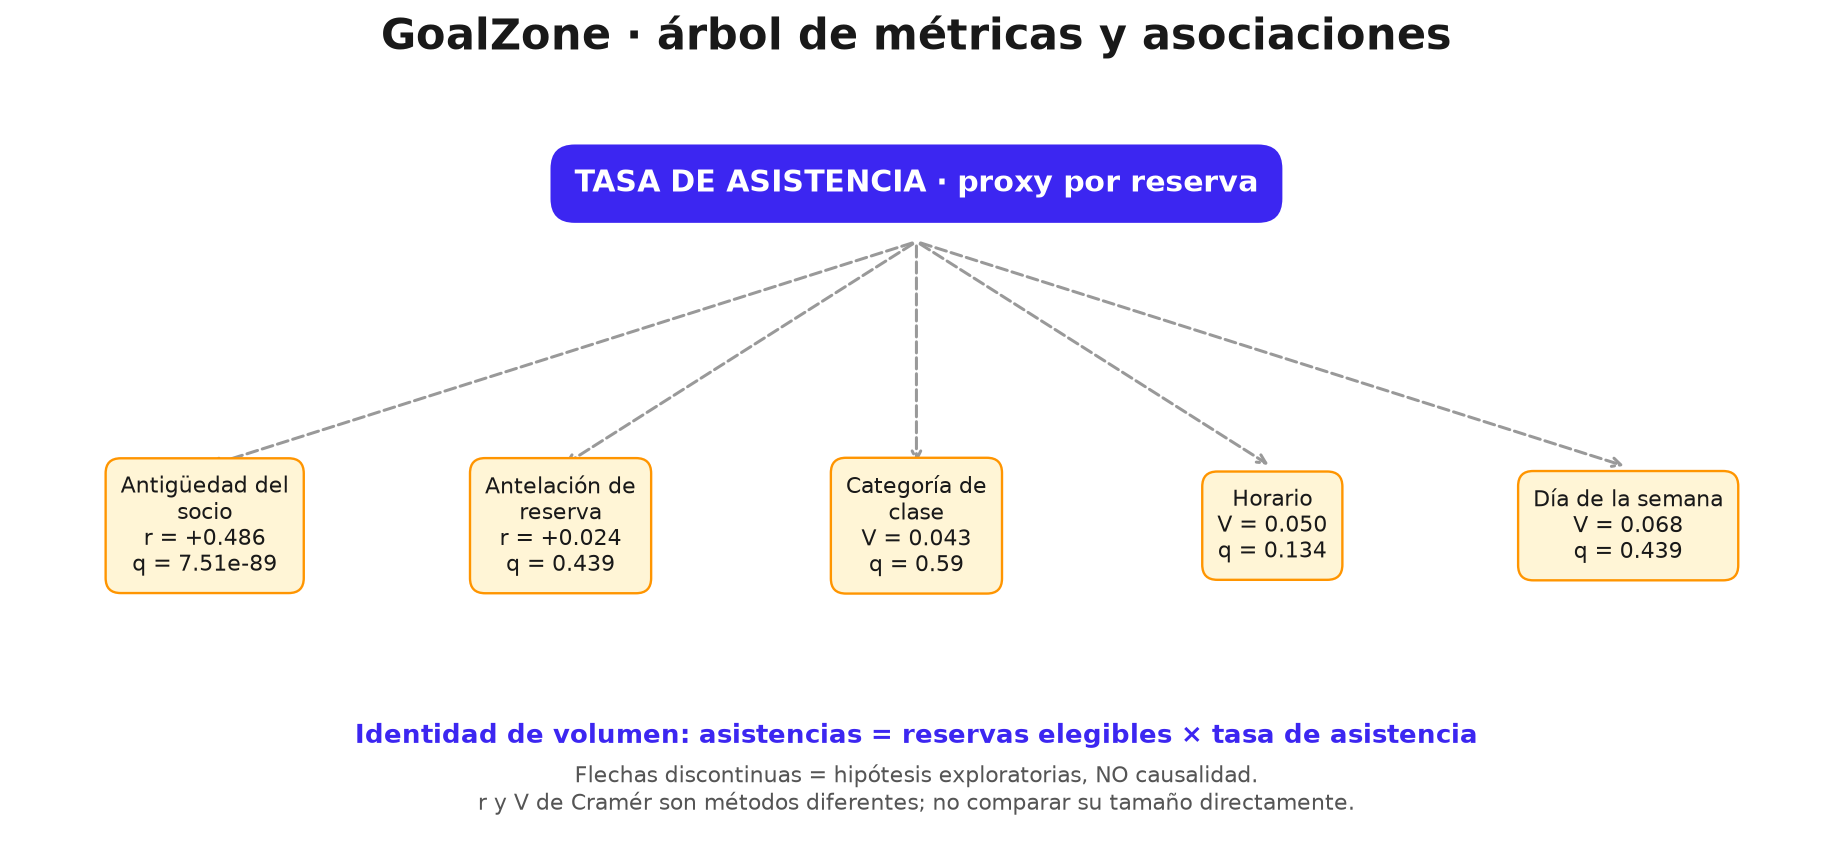

Exportados: arbol_goalzone.png, correlaciones_goalzone.csv, asistencia_por_antiguedad.csv, goalzone_interactivo.html


In [6]:
plot_tree(correlaciones, Path("arbol_goalzone.png"))
display(Image(filename="arbol_goalzone.png"))
correlaciones.to_csv("correlaciones_goalzone.csv", index=False)
segment_rates(df, "tenure_group").to_csv("asistencia_por_antiguedad.csv", index=False)
fig.write_html("goalzone_interactivo.html", include_plotlyjs=True, full_html=True)
print("Exportados: arbol_goalzone.png, correlaciones_goalzone.csv, asistencia_por_antiguedad.csv, goalzone_interactivo.html")

### 7. Preguntas para la discusión

1. ¿Cuál de las variables muestra la asociación más clara con `attended`? ¿Podemos intervenir sobre ella?
2. ¿Un q-value pequeño demuestra causalidad?
3. ¿Qué identificadores/eventos faltan para medir usuarios que disfrutan de clases satisfactorias cada semana?
4. ¿Cómo comprobarías si un mejor onboarding incrementa la asistencia? Plantea población, aleatorización, outcome y guardrails.

**Para la versión automatizada:** abre GitHub Actions y descarga el artefacto `analisis-goalzone`. Contiene además la guía de calidad y el informe HTML autónomo.